# Exploratory comparison of all eleven methods

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## What can be compared?
All final searches use the same per-run evaluation budget, but the six extension methods received extra development tuning. Treat the eleven-method comparison as exploratory. Never combine original three-seed runs with later benchmark runs.


In [2]:
summary=fitness_summary()
show_table(summary,limit=30)


method,regime,runs,best,median,mean,sample_sd,feasible
GA,nominal,30,0.0513596826213876,0.05226312547838116,0.05234592317298383,0.00047155332220080037,30
GA,robust,30,0.06573136108055574,0.06699187362751968,0.0670648903446438,0.0009680660401343237,30
PSO,nominal,30,0.05103350348240746,0.052025843178989103,0.051917325210781524,0.00046374850992765847,30
PSO,robust,30,0.06515258231085962,0.06573683780613984,0.06612486125976656,0.0009329427432311508,30
CSO,nominal,30,0.05797834584155963,0.06714704781071607,0.06894582617207273,0.006431856988668625,30
CSO,robust,30,0.07536530816958906,0.08594910805458739,0.0864914037604736,0.006837963816693089,30
DSA,nominal,30,0.05226800719584598,0.05702833085335258,0.05870858887815674,0.004588144239095514,30
DSA,robust,30,0.06650325721236684,0.07020261902729469,0.07004076356282862,0.002327064182525687,30
CMA-ES,nominal,30,0.05226415044430983,0.052958784530325265,0.053037539135384566,0.0005636200006585569,30
CMA-ES,robust,30,0.06540049914089047,0.06669607516221868,0.06679798006541089,0.0011446261578759687,30


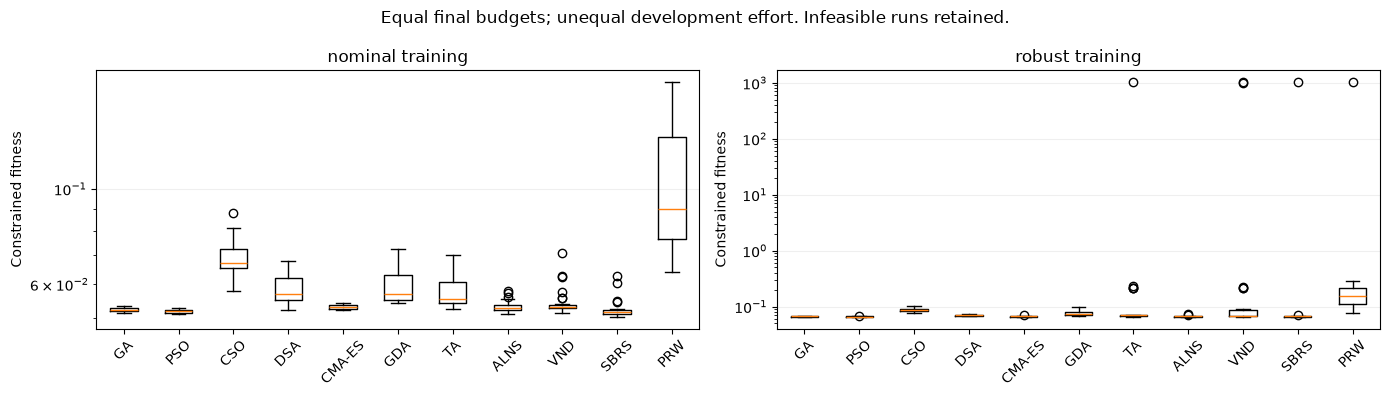

In [3]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,mode in zip(axes,['nominal','robust']):
    values=[np.array([r['fitness'] for _,r in load_runs(m,mode)]) for m in METHODS]
    ax.boxplot(values,tick_labels=list(METHODS),showfliers=True)
    ax.set(title=mode+' training',ylabel='Constrained fitness',yscale='log'); ax.tick_params(axis='x',rotation=45)
    ax.grid(axis='y',alpha=.2)
fig.suptitle('Equal final budgets; unequal development effort. Infeasible runs retained.')
fig.tight_layout(); plt.show(); plt.close(fig)


## Feasibility matters
Scores at or above 1,000 are penalized. This chart counts training-feasible runs; it does not count held-out passes.


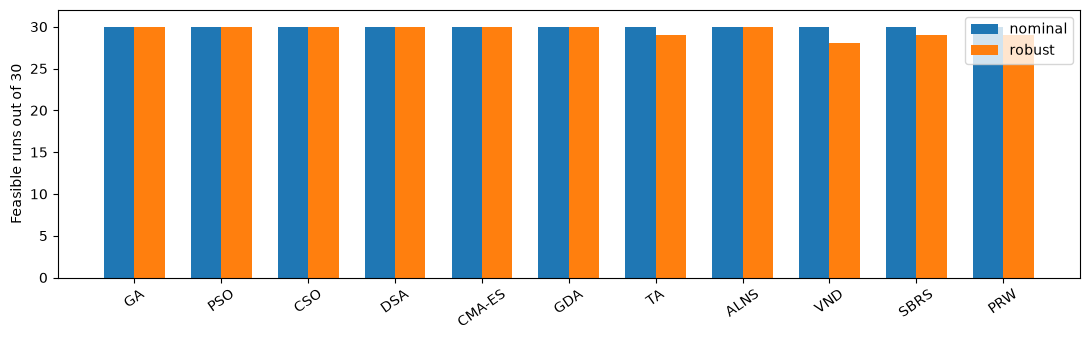

In [4]:
fig,ax=plt.subplots(figsize=(11,3.5)); x=np.arange(len(METHODS))
for i,mode in enumerate(['nominal','robust']):
    counts=[next(r['feasible'] for r in summary if r['method']==m and r['regime']==mode) for m in METHODS]
    ax.bar(x+(i-.5)*.35,counts,width=.35,label=mode)
ax.set_xticks(x,list(METHODS),rotation=35);ax.set(ylabel='Feasible runs out of 30',ylim=(0,32));ax.legend()
fig.tight_layout();plt.show();plt.close(fig)


## Paired comparisons and uncertainty
Friedman permutation tests and Holm-adjusted paired Wilcoxon tests concern optimizer seeds on this model. Their assumptions and comparison families matter. Bootstrap intervals are descriptive and not multiplicity-adjusted.


In [5]:
display(Code(json.dumps(load_json(study('ALNS')/'results/statistics.json'),indent=2),language='json'))
show_table(load_csv(NOMINAL/'results/paired_comparisons.csv'),limit=15)


{
  "tests": [
    {
      "scope": "new_six",
      "mode": "nominal",
      "friedman_statistic": 114.24761904761908,
      "permutation_p": 4.999750012499375e-05,
      "permutations": 20000
    },
    {
      "scope": "new_six",
      "mode": "robust",
      "friedman_statistic": 92.32380952380959,
      "permutation_p": 4.999750012499375e-05,
      "permutations": 20000
    },
    {
      "scope": "exploratory_eleven",
      "mode": "nominal",
      "friedman_statistic": 245.64242424242434,
      "permutation_p": 4.999750012499375e-05,
      "permutations": 20000
    },
    {
      "scope": "exploratory_eleven",
      "mode": "robust",
      "friedman_statistic": 202.0727272727272,
      "permutation_p": 4.999750012499375e-05,
      "permutations": 20000
    }
  ],
  "bootstrap_resamples": 10000,
  "seed": 12102026,
  "inference": "Across optimization seeds on this single model. Each scope/regime has its own Holm family. Wilcoxon assumes symmetric paired differences. Bootstrap confidence intervals are not multiplicity-adjusted.",
  "exploratory_caveat": "The original five algorithms did not receive the new four-setting development pilot. Equal final evaluation budgets do not imply equal total development effort."
}

A,B,mean_A_minus_B,median_A_minus_B,A_wins,ties,B_wins,wilcoxon_p,mean_difference_ci95_low,mean_difference_ci95_high,holm_p,holm_significant_0.05
GA,PSO,0.00042859796216666667,0.00028156316649999996,9,0,21,0.008142979815602303,0.0001663513946783333,0.0006938358266133332,0.008142979815602303,True
GA,CSO,-0.016599902999033335,-0.015237630419,30,0,0,1.862645149230957e-09,-0.0189691541314975,-0.014384325183555835,1.862645149230957e-08,True
GA,DSA,-0.006362665705133334,-0.004588463855,30,0,0,1.862645149230957e-09,-0.00798221534227167,-0.00481513734794,1.862645149230957e-08,True
GA,CMA-ES,-0.0006916159624,-0.000750954479,23,0,7,2.6885420083999634e-05,-0.0009527030192333334,-0.0004308359479891667,5.377084016799927e-05,True
PSO,CSO,-0.0170285009613,-0.015514102576,30,0,0,1.862645149230957e-09,-0.019324253056064163,-0.014879977874501665,1.862645149230957e-08,True
PSO,DSA,-0.006791263667433335,-0.005465541866,30,0,0,1.862645149230957e-09,-0.008459245832251668,-0.005163663319651667,1.862645149230957e-08,True
PSO,CMA-ES,-0.0011202139247333332,-0.0011647160945,30,0,0,1.862645149230957e-09,-0.0013552463110599996,-0.0008756348797041665,1.862645149230957e-08,True
CSO,DSA,0.010237237293900001,0.0104064713775,2,0,28,1.862645149230957e-08,0.007541456677773334,0.013116779286845834,7.450580596923828e-08,True
CSO,CMA-ES,0.01590828703673334,0.013958424478000001,0,0,30,1.862645149230957e-09,0.013774553284224167,0.018193035207391666,1.862645149230957e-08,True
DSA,CMA-ES,0.005671049742800001,0.004581179272,1,0,29,2.60770320892334e-08,0.004081528627910001,0.007291414767075834,7.82310962677002e-08,True
